# 20 · A5: general land maps for rare classes (prior correction, multinomial)

Fixed in `PLAN.md` (amendment A5) before this notebook ran. Matt: *"I don't want hacks, ideally we want a
method that doesn't have rules for certain stuff"*; then *"yes"* to testing two general methods, each applied the
same way to every class:

- **(0) current:** notebook 12's one-vs-rest logistic classifiers (each fitted on a near-50/50 sample), p > 0.5;
- **(1) prior-corrected:** the same classifiers, intercepts shifted by log-odds(true share) − log-odds(training
  share) (Saerens, Latinne & Decaestecker 2002, *Neural Computation* 14(1):21–41), p > 0.5;
- **(2) multinomial:** one softmax logistic regression fitted on 500,000 training pixels in their natural
  proportions; each pixel's class is the argmax.

Scored on the **held-out states** (Minnesota, Georgia) against the official maps at 90 m: per-class F1 and
macro-F1 (M1), and the persona and demo questions (M2).

In [1]:
import json
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from askmap.config import PROJECT_ROOT, data_root, load_config, load_env
from askmap.demo.engine import Engine
from askmap.demo.serve import load_tiles, make_contexts
from askmap.landmaps import (
    argmax_onehot,
    block_counts,
    bootstrap_macro_diff,
    class_scores,
    fit_multinomial,
    macro_f1,
    natural_sample,
    ovr_probs,
    ovr_training_share,
    prior_shift,
)
from askmap.layers import SOLAR_LATER, official_leaf_map
from askmap.plan import execute
from askmap.score import pooled_counts
from askmap.tiles import area_tiles

load_env()
cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
CAP = load_config(PROJECT_ROOT / "configs" / "captions.yaml")
QUERIES = load_config(PROJECT_ROOT / "configs" / "queries.yaml")["queries"]
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
DEMO = ROOT / "demo"
meta = json.loads((DEMO / "meta.json").read_text())
CL, CLS = cfg["classes"], cfg["classifier"]
LEAVES = CL["leaves"]
OTHER = LEAVES.index("other")
HELD = cfg["heldout_pools"]  # question area -> held-out state
SEEN = list(HELD)
STRIDE = meta["stride"]
N_SAMPLE, SEED, BLOCK, NB, MIN_TRUE = 500_000, 0, 10, 1000, 50
METHODS = ["current", "prior_corrected", "multinomial"]
T_START = time.time()

## Training tiles: class shares, and the shares the one-vs-rest classifiers were fitted on

In [2]:
embs, labs, keeps = [], [], []
for area, acfg in cfg["areas"].items():
    for name, (_tile, role) in area_tiles(acfg, cfg["grid"]).items():
        if role != "train":
            continue
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        embs.append(z["ae"].astype(np.float32))
        labs.append(official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar))
        k = np.ones(labs[-1].shape, bool)
        if solar is not None:
            k &= solar != SOLAR_LATER
        keeps.append(k)
counts = np.zeros(len(LEAVES), np.int64)
for a, lab, k in zip(embs, labs, keeps, strict=True):
    ok = k & np.isfinite(a).all(axis=0)
    counts += np.bincount(lab[ok].ravel(), minlength=len(LEAVES))
TRUE_SHARE = counts / counts.sum()
TRAIN_SHARE = ovr_training_share(counts, CLS["per_class"])
TC = np.load(ROOT / "aether_us" / "tag_classifiers.npz")
COEF, ICPT0 = TC["coef"].astype(np.float64), TC["intercept"].astype(np.float64)
if list(TC["leaves"]) != LEAVES:
    raise ValueError("tag_classifiers.npz leaves differ from the configured leaves")
ICPT1 = ICPT0.copy()
fitted = ICPT0 > -50  # notebook 12 left "other" (and any empty class) unfitted at -50
ICPT1[fitted] = prior_shift(ICPT0[fitted], TRAIN_SHARE[fitted], TRUE_SHARE[fitted])
shares = pd.DataFrame(
    {
        "leaf": LEAVES,
        "pixels": counts,
        "true_share": TRUE_SHARE.round(5),
        "training_share": TRAIN_SHARE.round(4),
        "intercept_shift": (ICPT1 - ICPT0).round(2),
    }
)
print(f"{len(embs)} training tiles, {counts.sum():,} valid pixels")
shares

17 training tiles, 7,561,469 valid pixels


,leaf,pixels,true_share,training_share,intercept_shift
0,corn,1053224,0.13929,0.5000,-1.82
1,soybeans,1044987,0.13820,0.5000,-1.83
2,spring_wheat,88163,0.01166,0.5000,-4.44
3,sunflower,1697,0.00022,0.0782,-5.93
4,canola,4715,0.00062,0.1908,-5.93
5,cotton,168406,0.02227,0.5000,-3.78
6,other_crop,430253,0.05690,0.5000,-2.81
7,hay,110575,0.01462,0.5000,-4.21
8,grassland,1639334,0.21680,0.5000,-1.28
9,fallow,53483,0.00707,0.5000,-4.94


## Multinomial model on 500,000 pixels in natural proportions

In [3]:
t0 = time.time()
X, y = natural_sample(embs, labs, keeps, N_SAMPLE, SEED)
del embs, labs, keeps
MC, MI = fit_multinomial(X, y, len(LEAVES))
print(
    f"fitted on {len(X):,} pixels in {time.time() - t0:.0f} s; sample class counts:",
    dict(zip(LEAVES, np.bincount(y, minlength=len(LEAVES)).tolist(), strict=True)),
)
np.savez_compressed(
    ROOT / "aether_us" / "land_methods.npz",
    leaves=np.array(LEAVES),
    ovr_coef=COEF,
    ovr_intercept=ICPT0,
    prior_intercept=ICPT1,
    mn_coef=MC,
    mn_intercept=MI,
    true_share=TRUE_SHARE,
    training_share=TRAIN_SHARE,
)
del X, y

fitted on 500,000 pixels in 10 s; sample class counts: {'corn': 69399, 'soybeans': 69774, 'spring_wheat': 5833, 'sunflower': 132, 'canola': 315, 'cotton': 11195, 'other_crop': 28303, 'hay': 7160, 'grassland': 108420, 'fallow': 3460, 'forest': 90492, 'developed': 44669, 'water': 7466, 'wetland': 45646, 'solar_farm': 1297, 'other': 6439}


## Land maps of every method on the demo tiles (90 m), and check K5

In [4]:
TILES = load_tiles(DEMO, meta)
CTX = make_contexts(cfg, meta, DEMO)
PROBS = {m: {} for m in METHODS}
k5 = 0.0
for area, tiles in TILES.items():
    for t in tiles:
        ae = np.load(ROOT / "tiles" / f"{area}_{t.name}.npz")["ae"][:, ::STRIDE, ::STRIDE].astype(np.float32)
        PROBS["current"][t.name] = ovr_probs(COEF, ICPT0, ae)
        PROBS["prior_corrected"][t.name] = ovr_probs(COEF, ICPT1, ae)
        PROBS["multinomial"][t.name] = argmax_onehot(MC, MI, ae)
        d = np.abs(PROBS["current"][t.name] - t.probs.astype(np.float32))[:, t.valid].max()
        k5 = max(k5, float(d))
K5 = k5 < 0.01
print(f"K5: largest difference from the stored demo probabilities {k5:.5f} -> {'PASS' if K5 else 'FAIL'}")
if not K5:
    raise AssertionError("method (0) does not reproduce the demo's probabilities; nothing below is valid")

K5: largest difference from the stored demo probabilities 0.00024 -> PASS


## M1: per-class F1 and macro-F1 on the held-out states (pooled over Minnesota and Georgia)

In [5]:
def area_blocks(areas, method):
    out = []
    for area in areas:
        for t in TILES[area]:
            masks = PROBS[method][t.name] > 0.5
            out.append(block_counts(masks, t.leaf.astype(int), t.valid, BLOCK))
    return np.concatenate(out)


def evaluate(areas):
    blocks = {m: area_blocks(areas, m) for m in METHODS}
    true = blocks["current"].sum(0)[:, 0] + blocks["current"].sum(0)[:, 2]
    classes = np.array([i for i in range(len(LEAVES)) if i != OTHER and true[i] >= MIN_TRUE])
    rows = []
    for m in METHODS:
        s = class_scores(blocks[m].sum(0))
        for i in classes:
            rows.append(
                {
                    "method": m,
                    "leaf": LEAVES[i],
                    "true": int(s["true"][i]),
                    "predicted": int(s["predicted"][i]),
                    "precision": s["precision"][i],
                    "recall": s["recall"][i],
                    "f1": s["f1"][i],
                }
            )
    macro = {m: macro_f1(blocks[m].sum(0), classes) for m in METHODS}
    diffs = {m: bootstrap_macro_diff(blocks[m], blocks["current"], classes, NB, SEED) for m in METHODS[1:]}
    return pd.DataFrame(rows), macro, diffs, classes


HELD_AREAS = [HELD[a] for a in SEEN]
PER_CLASS, MACRO, DIFFS, CLASSES = evaluate(HELD_AREAS)
print("held-out classes scored:", [LEAVES[i] for i in CLASSES])
for m in METHODS:
    extra = (
        ""
        if m == "current"
        else (f"; difference {DIFFS[m][0]:+.3f} [{DIFFS[m][1]:+.3f}, {DIFFS[m][2]:+.3f}]")
    )
    print(f"{m:16s} macro-F1 {MACRO[m]:.3f}{extra}")
PER_CLASS.pivot_table(index="leaf", columns="method", values="f1")[METHODS].round(3)

held-out classes scored: ['corn', 'soybeans', 'spring_wheat', 'cotton', 'other_crop', 'hay', 'grassland', 'fallow', 'forest', 'developed', 'water', 'wetland', 'solar_farm']
current          macro-F1 0.549
prior_corrected  macro-F1 0.575; difference +0.026 [+0.011, +0.039]
multinomial      macro-F1 0.676; difference +0.127 [+0.109, +0.144]


method,current,prior_corrected,multinomial
leaf,,,
corn,0.885,0.916,0.918
cotton,0.596,0.853,0.834
developed,0.678,0.735,0.770
fallow,0.064,0.366,0.340
forest,0.754,0.719,0.763
grassland,0.634,0.517,0.691
hay,0.204,0.553,0.728
other_crop,0.625,0.301,0.786
solar_farm,0.435,0.036,0.464


In [6]:
focus = PER_CLASS[PER_CLASS.leaf.isin(["solar_farm", "wetland"])]
focus[["leaf", "method", "true", "predicted", "precision", "recall", "f1"]].round(3)

,leaf,method,true,predicted,precision,recall,f1
11,wetland,current,42184,93379,0.430,0.952,0.593
12,solar_farm,current,1591,3584,0.314,0.708,0.435
24,wetland,prior_corrected,42184,48497,0.665,0.765,0.712
25,solar_farm,prior_corrected,1591,29,1.000,0.018,0.036
37,wetland,multinomial,42184,47547,0.664,0.749,0.704
38,solar_farm,multinomial,1591,484,0.994,0.302,0.464


## Information: the same on the seen test tiles (North Dakota, North Carolina)

In [7]:
PC_SEEN, MACRO_SEEN, DIFFS_SEEN, _ = evaluate(SEEN)
for m in METHODS:
    extra = "" if m == "current" else f"; difference {DIFFS_SEEN[m][0]:+.3f}"
    print(f"{m:16s} macro-F1 {MACRO_SEEN[m]:.3f}{extra}")

current          macro-F1 0.561
prior_corrected  macro-F1 0.617; difference +0.056
multinomial      macro-F1 0.729; difference +0.168


## M2: persona and demo questions in the held-out states

Each plan is answered in the held-out pool of its question area. Answer key = the plan on the official 90 m maps;
prediction = the demo engine's `answer_masks` with the method's maps. Scored if the key has ≥ 50 cells.

In [8]:
DEMO_QS = [
    (
        "demo_solar",
        "forest within 500 m of a solar farm",
        "georgia",
        {
            "land": {"classes": ["forest"], "min_patch_ha": None},
            "near": [{"classes": ["solar_farm"], "distance_m": 500, "negate": False}],
            "climate": [],
        },
    ),
    (
        "demo_hay",
        "hay fields within 200 m of a wetland",
        "minnesota",
        {
            "land": {"classes": ["hay"], "min_patch_ha": None},
            "near": [{"classes": ["wetland"], "distance_m": 200, "negate": False}],
            "climate": [],
        },
    ),
    (
        "demo_soy",
        "soybean fields more than 300 m from any wetland or open water",
        "minnesota",
        {
            "land": {"classes": ["soybeans"], "min_patch_ha": None},
            "near": [{"classes": ["wetland", "water"], "distance_m": 300, "negate": True}],
            "climate": [],
        },
    ),
]
QS = [(q["id"], q["question"], HELD[q["plan"]["area"]], q["plan"]) for q in QUERIES]
QS += [(i, text, area, dict(plan, area=area, output="map")) for i, text, area, plan in DEMO_QS]
ENGINES = {}
for m in METHODS:
    tiles_m = {
        a: [replace(t, probs=PROBS[m][t.name].astype(np.float16)) for t in ts] for a, ts in TILES.items()
    }
    ENGINES[m] = Engine(tiles_m, LEAVES, None, None, CTX, meta["best"], CAP, top_share=meta["top_share"])
rows = []
for qid, text, area, plan in QS:
    tiles = TILES[area]
    truth = execute(plan, {t.name: t.leaf.astype(np.int16) for t in tiles}, CTX[area])
    valid = {t.name: t.valid for t in tiles}
    n_true = int(sum(truth[t.name][t.valid].sum() for t in tiles))
    row = {"id": qid, "area": area, "question": text, "true": n_true, "scored": n_true >= MIN_TRUE}
    for m in METHODS:
        c = pooled_counts(ENGINES[m].answer_masks(plan, area), truth, valid)
        row[f"f1_{m}"], row[f"precision_{m}"], row[f"predicted_{m}"] = c["f1"], c["precision"], c["predicted"]
    rows.append(row)
QDF = pd.DataFrame(rows)
SC = QDF[QDF.scored]
print(f"{len(QDF)} questions, {len(SC)} scored (answer key >= {MIN_TRUE} cells)")
M2 = {}
for m in METHODS[1:]:
    d = (SC[f"f1_{m}"] - SC["f1_current"]).to_numpy()
    r = np.random.default_rng(SEED)
    boot = [np.median(d[r.integers(0, len(d), len(d))]) for _ in range(NB)]
    M2[m] = {
        "median_diff": float(np.median(d)),
        "lo": float(np.percentile(boot, 2.5)),
        "hi": float(np.percentile(boot, 97.5)),
        "share_worse_by_0.10": float(np.mean(d < -0.10)),
        "median_f1": float(SC[f"f1_{m}"].median()),
    }
    print(
        f"{m:16s} median F1 {M2[m]['median_f1']:.3f} (current {SC['f1_current'].median():.3f}); median "
        f"difference {M2[m]['median_diff']:+.3f} [{M2[m]['lo']:+.3f}, {M2[m]['hi']:+.3f}]; worse by >0.10: "
        f"{M2[m]['share_worse_by_0.10']:.0%}"
    )

61 questions, 39 scored (answer key >= 50 cells)
prior_corrected  median F1 0.537 (current 0.499); median difference +0.017 [-0.025, +0.050]; worse by >0.10: 21%
multinomial      median F1 0.701 (current 0.499); median difference +0.104 [+0.082, +0.156]; worse by >0.10: 3%


In [9]:
QDF[QDF.id.str.startswith("demo")][
    ["id", "area", "true"] + [f"{k}_{m}" for m in METHODS for k in ("predicted", "precision", "f1")]
].round(3)

,id,area,true,predicted_current,precision_current,f1_current,predicted_prior_corrected,precision_prior_corrected,f1_prior_corrected,predicted_multinomial,precision_multinomial,f1_multinomial
58,demo_solar,georgia,735,19304,0.030,0.057,74,0.824,0.151,667,0.459,0.437
59,demo_hay,minnesota,197,10756,0.015,0.030,702,0.100,0.156,248,0.282,0.315
60,demo_soy,minnesota,13853,11449,0.833,0.754,13565,0.857,0.848,13365,0.874,0.858


## Verdicts

In [10]:
verdict = {"K5": {"max_abs_diff": k5, "pass": K5}, "methods": {}}
for m in METHODS[1:]:
    p, lo, hi = DIFFS[m]
    m1 = bool(p >= 0.03 and lo > 0)
    m2 = bool(M2[m]["median_diff"] >= 0.05 and M2[m]["share_worse_by_0.10"] <= 0.10)
    verdict["methods"][m] = {
        "macro_f1": MACRO[m],
        "macro_f1_current": MACRO["current"],
        "M1_diff": p,
        "M1_lo": lo,
        "M1_hi": hi,
        "M1": m1,
        **{f"M2_{k}": v for k, v in M2[m].items()},
        "M2": m2,
        "pass": m1 and m2,
    }
passing = [m for m in METHODS[1:] if verdict["methods"][m]["pass"]]
verdict["chosen"] = max(passing, key=lambda m: verdict["methods"][m]["M1_diff"]) if passing else None
verdict["seen_macro_f1"] = MACRO_SEEN
verdict["minutes"] = round((time.time() - T_START) / 60, 1)
(RES / "20_verdicts.json").write_text(json.dumps(verdict, indent=1))
PER_CLASS.to_csv(RES / "20_per_class_heldout.csv", index=False)
QDF.to_csv(RES / "20_questions.csv", index=False)
shares.to_csv(RES / "20_shares.csv", index=False)
for m, v in verdict["methods"].items():
    print(
        f"{m}: M1 {'PASS' if v['M1'] else 'FAIL'}, M2 {'PASS' if v['M2'] else 'FAIL'} -> "
        f"{'PASS' if v['pass'] else 'FAIL'}"
    )
print("chosen:", verdict["chosen"], f"| run time {verdict['minutes']} min")

prior_corrected: M1 FAIL, M2 FAIL -> FAIL
multinomial: M1 PASS, M2 PASS -> PASS
chosen: multinomial | run time 0.3 min


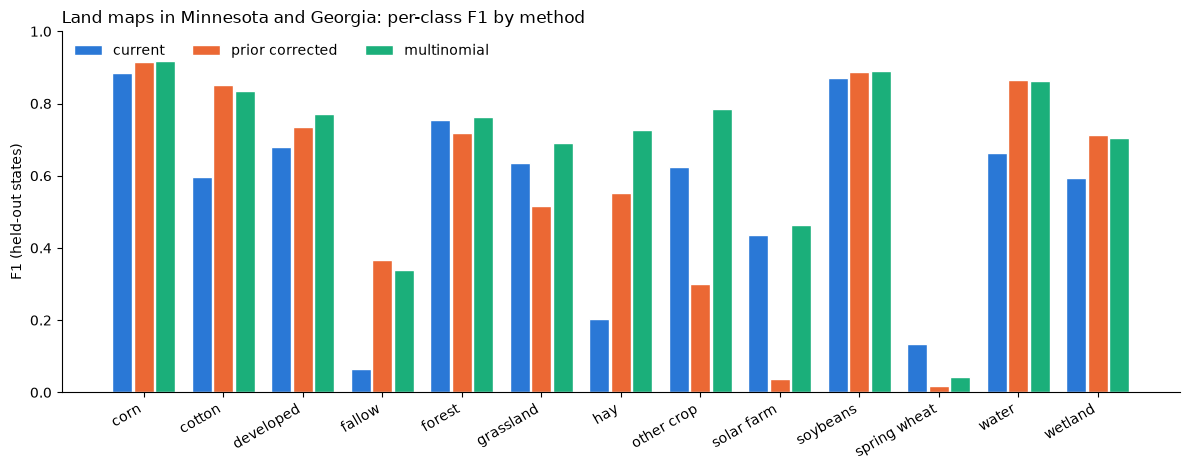

In [11]:
COL = {"current": "#2a78d6", "prior_corrected": "#eb6834", "multinomial": "#1baf7a"}
piv = PER_CLASS.pivot_table(index="leaf", columns="method", values="f1")[METHODS]
fig, ax = plt.subplots(figsize=(12, 4.8))
x = np.arange(len(piv))
for j, m in enumerate(METHODS):
    ax.bar(x + (j - 1) * 0.27, piv[m], width=0.25, color=COL[m], label=m.replace("_", " "), edgecolor="white")
ax.set_xticks(x, [s.replace("_", " ") for s in piv.index], rotation=30, ha="right")
ax.set_ylabel("F1 (held-out states)")
ax.set_ylim(0, 1)
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("Land maps in Minnesota and Georgia: per-class F1 by method", loc="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "20_per_class_f1.png", dpi=150)